In [ ]:
!pip install qiskit qiskit-algorithms qiskit-nature matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 23.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 44.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 48.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [qiskit-nature]


In [ ]:
!pip install -q "qiskit-nature[pyscf]" qiskit-algorithms scipy matplotlib

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit.primitives import StatevectorEstimator
from qiskit_algorithms import VQE, NumPyMinimumEigensolver
from qiskit_algorithms.optimizers import SLSQP

from qiskit_nature.units import DistanceUnit
from qiskit_nature.second_q.drivers import PySCFDriver
from qiskit_nature.second_q.mappers import JordanWignerMapper
from qiskit_nature.second_q.circuit.library import UCCSD, HartreeFock
from qiskit_nature.second_q.algorithms import GroundStateEigensolver

print("Semua library berhasil di-import!")

Semua library berhasil di-import!


In [ ]:
driver = PySCFDriver(
    atom="H 0 0 0; H 0 0 0.735",
    basis="sto-3g",
    charge=0,
    spin=0,
    unit=DistanceUnit.ANGSTROM
)

problem = driver.run()

print("Jumlah elektron:", problem.num_particles)
print("Jumlah orbital spasial:", problem.num_spatial_orbitals)
print("Jumlah spin-orbital:", problem.num_spin_orbitals)
print(
    "Energi tolakan inti:",
    problem.nuclear_repulsion_energy,
    "Hartree"
)

Jumlah elektron: (1, 1)
Jumlah orbital spasial: 2
Jumlah spin-orbital: 4
Energi tolakan inti: 0.7199689944489797 Hartree


In [ ]:
mapper = JordanWignerMapper()

# Hamiltonian dalam second quantization
fermionic_hamiltonian = problem.hamiltonian.second_q_op()

# Transformasi Jordan-Wigner
qubit_hamiltonian = mapper.map(fermionic_hamiltonian)

print("Hamiltonian dalam bentuk operator Pauli:")
print(qubit_hamiltonian)

print("\nJumlah qubit:", qubit_hamiltonian.num_qubits)
print("Jumlah suku Pauli:", len(qubit_hamiltonian))

Hamiltonian dalam bentuk operator Pauli:
SparsePauliOp(['IIII', 'IIIZ', 'IIZI', 'IZII', 'ZIII', 'IIZZ', 'IZIZ', 'ZIIZ', 'YYYY', 'XXYY', 'YYXX', 'XXXX', 'IZZI', 'ZIZI', 'ZZII'],
              coeffs=[-0.81054798+0.j,  0.17218393+0.j, -0.22575349+0.j,  0.17218393+0.j,
 -0.22575349+0.j,  0.12091263+0.j,  0.16892754+0.j,  0.16614543+0.j,
  0.0452328 +0.j,  0.0452328 +0.j,  0.0452328 +0.j,  0.0452328 +0.j,
  0.16614543+0.j,  0.17464343+0.j,  0.12091263+0.j])

Jumlah qubit: 4
Jumlah suku Pauli: 15


In [ ]:
hf_state = HartreeFock(
    problem.num_spatial_orbitals,
    problem.num_particles,
    mapper
)

ansatz = UCCSD(
    problem.num_spatial_orbitals,
    problem.num_particles,
    mapper,
    initial_state=hf_state
)

print("Jumlah qubit Ansatz:", ansatz.num_qubits)
print("Jumlah parameter variational:", ansatz.num_parameters)

# Visualisasi quantum circuit
print(ansatz.decompose(reps=2).draw(output="text"))

Jumlah qubit Ansatz: 4
Jumlah parameter variational: 3
     ┌──────────┐┌────┐┌───┐┌────────────┐┌───┐┌──────┐┌───┐ ┌───┐»
q_0: ┤ U(π,0,π) ├┤ √X ├┤ X ├┤ Rz(1*t[0]) ├┤ X ├┤ √Xdg ├┤ H ├─┤ X ├»
     └──┬───┬───┘└────┘└─┬─┘└────────────┘└─┬─┘└┬───┬─┘├───┴┐└─┬─┘»
q_1: ───┤ H ├────────────■──────────────────■───┤ H ├──┤ √X ├──■──»
     ┌──┴───┴───┐┌────┐┌───┐┌────────────┐┌───┐┌┴───┴─┐├───┬┘┌───┐»
q_2: ┤ U(π,0,π) ├┤ √X ├┤ X ├┤ Rz(1*t[1]) ├┤ X ├┤ √Xdg ├┤ H ├─┤ X ├»
     └──┬───┬───┘└────┘└─┬─┘└────────────┘└─┬─┘└┬───┬─┘├───┴┐└─┬─┘»
q_3: ───┤ H ├────────────■──────────────────■───┤ H ├──┤ √X ├──■──»
        └───┘                                   └───┘  └────┘     »
«     ┌───────────────┐┌───┐ ┌───┐  ┌────┐          ┌───┐┌──────────────────┐»
«q_0: ┤ Rz((-1)*t[0]) ├┤ X ├─┤ H ├──┤ √X ├──────────┤ X ├┤ Rz((-0.25)*t[2]) ├»
«     └───────────────┘└─┬─┘┌┴───┴─┐├───┬┘     ┌───┐└─┬─┘└──────────────────┘»
«q_1: ───────────────────■──┤ √Xdg ├┤ H ├──────┤ X ├──■──────────────────────»
«     ┌──────────

In [ ]:
# Menyimpan hasil setiap iterasi
energies = []

def store_intermediate_result(
    eval_count,
    parameters,
    mean,
    metadata
):
    energies.append(float(np.real(mean)))

# Estimator ideal
estimator = StatevectorEstimator()

# Classical optimizer
optimizer = SLSQP(maxiter=200)

# VQE
vqe = VQE(
    estimator=estimator,
    ansatz=ansatz,
    optimizer=optimizer,
    callback=store_intermediate_result
)

# Memulai dari Hartree-Fock state
vqe.initial_point = np.zeros(ansatz.num_parameters)

# Menghubungkan VQE dengan problem kimia
solver = GroundStateEigensolver(
    mapper,
    vqe
)

# Menjalankan optimisasi
vqe_result = solver.solve(problem)

print("VQE berhasil dijalankan!")

/usr/local/lib/python3.13/dist-packages/scipy/sparse/linalg/_dsolve/linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/usr/local/lib/python3.13/dist-packages/scipy/sparse/linalg/_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)


VQE berhasil dijalankan!


In [ ]:
electronic_energy = vqe_result.electronic_energies[0]
nuclear_energy = problem.nuclear_repulsion_energy
total_energy = vqe_result.total_energies[0]

print("===== HASIL VQE H2 =====")
print(f"Energi elektronik : {electronic_energy:.10f} Ha")
print(f"Energi tolakan inti: {nuclear_energy:.10f} Ha")
print(f"Energi total      : {total_energy:.10f} Ha")

===== HASIL VQE H2 =====
Energi elektronik : -1.8572750301 Ha
Energi tolakan inti: 0.7199689944 Ha
Energi total      : -1.1373060357 Ha


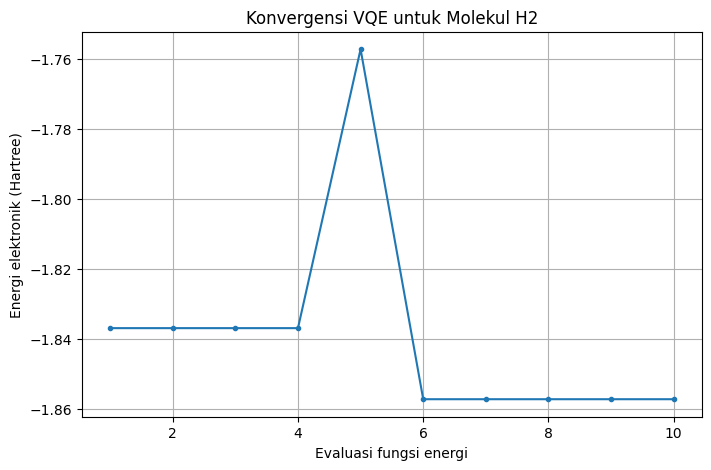

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(energies) + 1),
    energies,
    marker="o",
    markersize=3
)

plt.xlabel("Evaluasi fungsi energi")
plt.ylabel("Energi elektronik (Hartree)")
plt.title("Konvergensi VQE untuk Molekul H2")
plt.grid(True)

plt.show()

In [ ]:
# Membuat exact solver
exact_solver = GroundStateEigensolver(
    mapper,
    NumPyMinimumEigensolver()
)

# Menyelesaikan problem secara eksak
exact_result = exact_solver.solve(problem)

exact_energy = exact_result.total_energies[0]

print("===== PERBANDINGAN ENERGI =====")
print(f"Energi VQE   : {total_energy:.10f} Ha")
print(f"Energi Exact : {exact_energy:.10f} Ha")

error = abs(total_energy - exact_energy)

print(f"Absolute error: {error:.10e} Ha")

===== PERBANDINGAN ENERGI =====
Energi VQE   : -1.1373060357 Ha
Energi Exact : -1.1373060358 Ha
Absolute error: 5.7401638998e-11 Ha


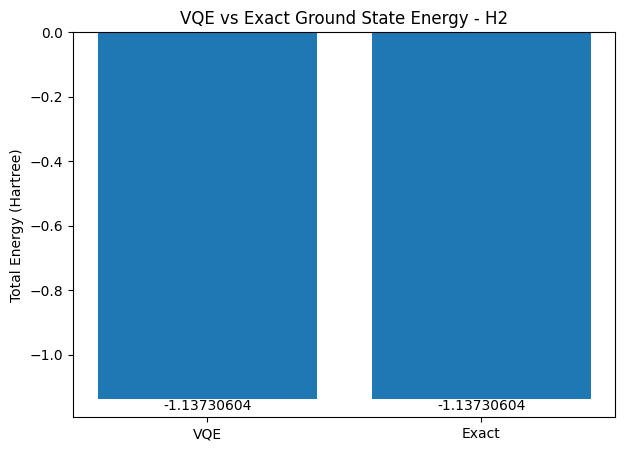

In [ ]:
plt.figure(figsize=(7, 5))

labels = ["VQE", "Exact"]
values = [total_energy, exact_energy]

plt.bar(labels, values)

plt.ylabel("Total Energy (Hartree)")
plt.title("VQE vs Exact Ground State Energy - H2")

for i, value in enumerate(values):
    plt.text(i, value, f"{value:.8f}", ha="center", va="top")

plt.show()

In [ ]:
print("Jumlah evaluasi energi:", len(energies))
print("Energi awal:", energies[0], "Ha")
print("Energi akhir:", energies[-1], "Ha")
print("Energi referensi:", exact_energy, "Ha")

Jumlah evaluasi energi: 10
Energi awal: -1.8369679912029837 Ha
Energi akhir: -1.857275030144979 Ha
Energi referensi: -1.1373060357534008 Ha


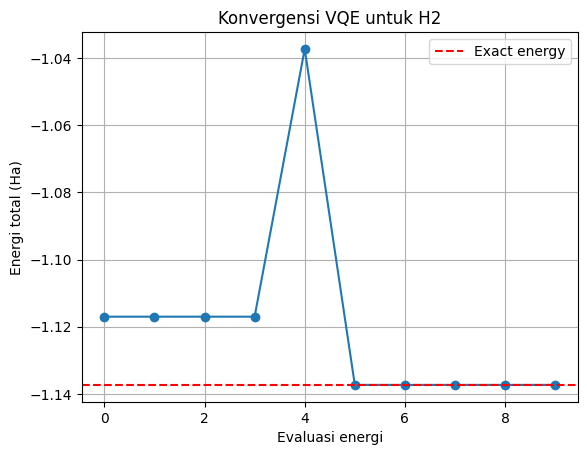

In [ ]:
nuclear_energy = problem.nuclear_repulsion_energy

total_energies_history = [
    energy + nuclear_energy for energy in energies
]

plt.plot(total_energies_history, marker='o')
plt.axhline(
    y=exact_energy,
    color='red',
    linestyle='--',
    label='Exact energy'
)

plt.xlabel("Evaluasi energi")
plt.ylabel("Energi total (Ha)")
plt.title("Konvergensi VQE untuk H2")
plt.legend()
plt.grid()
plt.show()